# EDA та моделі на single-qubit датасеті (data/raw/)

Той самий підхід, що й у [`eda_baseline_models.ipynb`](eda_baseline_models.ipynb), застосований до
значно ширшого [`data/raw/single_qubit_dataset.csv`](../data/raw/README.md) (315 000 рядків,
5000 унікальних одно-кубітних схем × 21 рівень шуму × 3 варіанти `shots`). На відміну від основного
датасету, тут `shots` варіюється (256/1024/4096) — це єдиний набір, на якому можна перевірити
залежність похибки від кількості вимірювань, що в основному датасеті було неможливо.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

df = pd.read_csv("../data/raw/single_qubit_dataset.csv")
df["noise_probability"] = df["noise_params"].apply(lambda s: json.loads(s)["probability"])
df.head()

,record_id,circuit_id,circuit_type,n_qubits,circuit_depth,single_qubit_gate_count,cx_count,mean_rotation_angle,observable,circuit_params,noise_category,noise_params,backend_name,shots,seed,ideal_expval,noisy_expval,delta,timestamp,noise_probability
0,c38d38f532d1c830_0.001_256,c38d38f532d1c830,mixed_rotation,1,2,2,0,2.8953,Z,"{""gates"": [{""gate"": ""RX"", ""theta"": 1.538700897...",depolarizing,"{""probability"": 0.001}",AerSimulator,256,373399426,-0.0143,-0.0625,0.0482,2026-10-23T22:45:34.507022+00:00,0.0010
1,c38d38f532d1c830_0.001_1024,c38d38f532d1c830,mixed_rotation,1,2,2,0,2.8953,Z,"{""gates"": [{""gate"": ""RX"", ""theta"": 1.538700897...",depolarizing,"{""probability"": 0.001}",AerSimulator,1024,1812140441,-0.0143,0.0293,-0.0436,2026-10-23T22:45:34.512043+00:00,0.0010
2,c38d38f532d1c830_0.001_4096,c38d38f532d1c830,mixed_rotation,1,2,2,0,2.8953,Z,"{""gates"": [{""gate"": ""RX"", ""theta"": 1.538700897...",depolarizing,"{""probability"": 0.001}",AerSimulator,4096,136505587,-0.0143,0.0083,-0.0226,2026-10-23T22:45:34.522484+00:00,0.0010
3,c38d38f532d1c830_0.002_256,c38d38f532d1c830,mixed_rotation,1,2,2,0,2.8953,Z,"{""gates"": [{""gate"": ""RX"", ""theta"": 1.538700897...",depolarizing,"{""probability"": 0.002}",AerSimulator,256,127978094,-0.0143,-0.0625,0.0482,2026-10-23T22:45:34.526238+00:00,0.0020
4,c38d38f532d1c830_0.002_1024,c38d38f532d1c830,mixed_rotation,1,2,2,0,2.8953,Z,"{""gates"": [{""gate"": ""RX"", ""theta"": 1.538700897...",depolarizing,"{""probability"": 0.002}",AerSimulator,1024,402418010,-0.0143,-0.0117,-0.0025,2026-10-23T22:45:34.530776+00:00,0.0020


## 1. Перевірка якості датасету

In [2]:
print("Розмір:", df.shape)
print("Пропуски:", df.isnull().sum().sum())
print("Дублікати record_id:", df.duplicated(subset=["record_id"]).sum())
print("Унікальних схем (circuit_id):", df["circuit_id"].nunique())
print("Рядків на одну схему:", df.groupby("circuit_id").size().unique())
print("\nТипи схем:\n", df["circuit_type"].value_counts())
print("\nВаріанти shots:\n", df["shots"].value_counts())
print("\nУнікальних рівнів шуму:", df["noise_probability"].nunique())

Розмір: (315000, 20)
Пропуски: 0
Дублікати record_id: 0
Унікальних схем (circuit_id): 5000
Рядків на одну схему: [63]

Типи схем:
 circuit_type
fixed_angle       291123
mixed_rotation     23877
Name: count, dtype: int64

Варіанти shots:
 shots
256     105000
1024    105000
4096    105000
Name: count, dtype: int64

Унікальних рівнів шуму: 21


**Висновок:** без пропусків і дублікатів, 5000 унікальних схем, по 63 рядки кожна
(21 рівень шуму × 3 shots) — узгоджено з кодом генерації (`src/data_generation/dataset_builder.py`).

## 2. Розподіл `delta` та залежність від шуму, shots і глибини

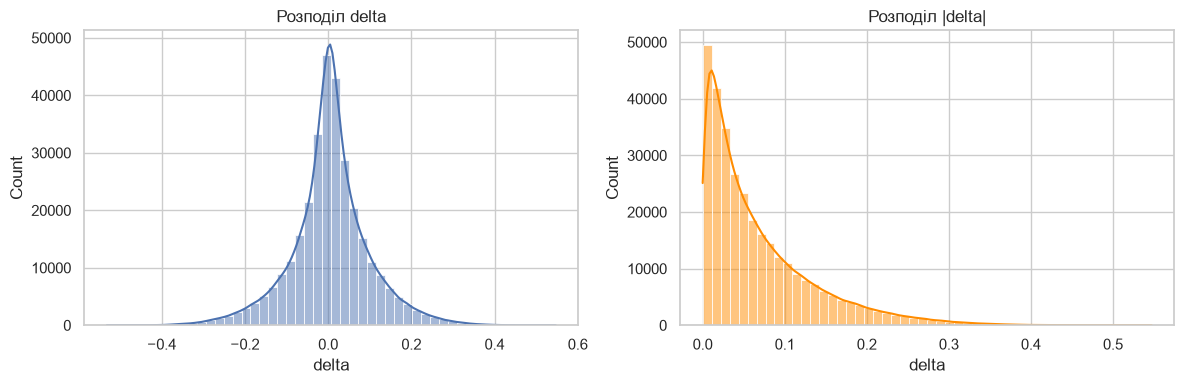

count   315000.0000
mean         0.0048
std          0.0950
min         -0.5320
25%         -0.0396
50%          0.0045
75%          0.0512
max          0.5470
Name: delta, dtype: float64

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["delta"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Розподіл delta")
sns.histplot(df["delta"].abs(), bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Розподіл |delta|")
plt.tight_layout()
plt.show()
df["delta"].describe()

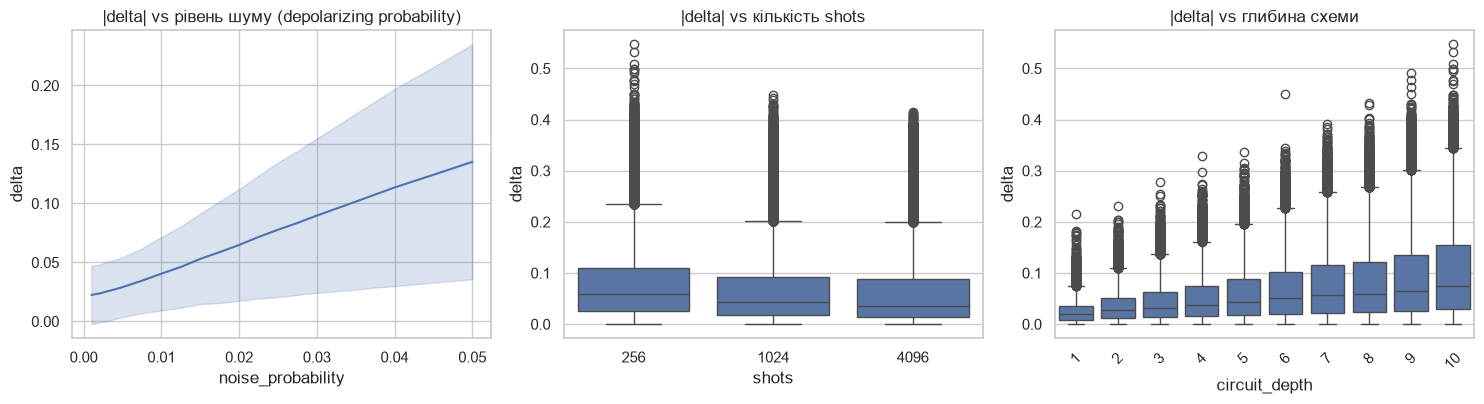

Кореляція з |delta|:
noise_probability          0.5252
circuit_depth              0.3243
single_qubit_gate_count    0.3243
mean_rotation_angle       -0.0406
shots                     -0.0868
Name: abs_delta, dtype: float64

Середня |delta| за кількістю shots (чим більше shots, тим менше похибки вимірювання):
shots
256    0.0774
1024   0.0654
4096   0.0609
Name: delta, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sns.lineplot(data=df, x="noise_probability", y=df["delta"].abs(), ax=axes[0], errorbar="sd")
axes[0].set_title("|delta| vs рівень шуму (depolarizing probability)")

sns.boxplot(data=df, x="shots", y=df["delta"].abs(), ax=axes[1])
axes[1].set_title("|delta| vs кількість shots")

sns.boxplot(data=df, x="circuit_depth", y=df["delta"].abs(), ax=axes[2])
axes[2].set_title("|delta| vs глибина схеми")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

corr = df[["noise_probability", "shots", "circuit_depth", "single_qubit_gate_count", "mean_rotation_angle"]].assign(
    abs_delta=df["delta"].abs()
).corr()["abs_delta"].drop("abs_delta")
print("Кореляція з |delta|:")
print(corr.sort_values(ascending=False))

print("\nСередня |delta| за кількістю shots (чим більше shots, тим менше похибки вимірювання):")
print(df.groupby("shots")["delta"].apply(lambda s: s.abs().mean()))

**Висновок з EDA:** нарешті видно пряму залежність від `shots` — середня `|delta|` падає з
0.077 (256 shots) до 0.061 (4096 shots), саме так, як і мало бути (більше вимірювань → менше
статистичного шуму). Рівень шуму (`noise_probability`) — найсильніший корелят (0.53), глибина схеми
теж помітно впливає (0.32). На перший погляд дані виглядають придатними для регресії не гірше за
основний датасет.

## 3. Ознаки, ціль, розділення train/validation/test

На відміну від основного датасету тут немає готового стовпця `split` — тому розділяємо самі,
групуючи за `circuit_id` (80/10/10), щоб жодна схема не потрапила одночасно в кілька частин.

In [5]:
num_features = ["circuit_depth", "single_qubit_gate_count", "mean_rotation_angle", "noise_probability", "shots"]
cat_features = ["circuit_type"]
features = num_features + cat_features
target = "delta"

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df["circuit_id"]))
train, temp = df.iloc[train_idx], df.iloc[temp_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp, groups=temp["circuit_id"]))
val, test = temp.iloc[val_idx], temp.iloc[test_idx]

print(f"train: {len(train)}, validation: {len(val)}, test: {len(test)}")
print("Перетин circuit_id між train і test:", len(set(train.circuit_id) & set(test.circuit_id)))

train: 252000, validation: 31500, test: 31500
Перетин circuit_id між train і test: 0


## 4. Моделі

In [6]:
def make_pipeline(model):
    pre = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)],
        remainder="passthrough",
    )
    return Pipeline([("pre", pre), ("scale", StandardScaler(with_mean=False)), ("model", model)])


models = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42, n_jobs=-1),
    "Small MLP": MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42, early_stopping=True),
}

def evaluate(pipe, X, y):
    pred = pipe.predict(X)
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
        "R2": r2_score(y, pred),
    }

fitted = {}
rows = []
for name, model in models.items():
    pipe = make_pipeline(model)
    pipe.fit(train[features], train[target])
    fitted[name] = pipe
    for split_name, split_df in [("validation", val), ("test", test)]:
        rows.append({"model": name, "split": split_name, **evaluate(pipe, split_df[features], split_df[target])})

results = pd.DataFrame(rows)
results

,model,split,MAE,RMSE,R2
0,Dummy (mean),validation,0.0636,0.0881,-0.0047
1,Dummy (mean),test,0.0664,0.0939,-0.0004
2,Linear Regression,validation,0.0637,0.0881,-0.0056
3,Linear Regression,test,0.0663,0.0938,0.0016
4,Ridge (alpha=1.0),validation,0.0637,0.0881,-0.0056
5,Ridge (alpha=1.0),test,0.0663,0.0938,0.0016
6,Random Forest,validation,0.0652,0.0906,-0.0628
7,Random Forest,test,0.0681,0.0984,-0.0985
8,XGBoost,validation,0.0653,0.0907,-0.0656
9,XGBoost,test,0.0672,0.0959,-0.0434


In [7]:
raw_mae_test = test["delta"].abs().mean()
print(f"Без корекції (raw) на test: MAE={raw_mae_test:.4f}")
comparison_test = results[results["split"] == "test"].drop(columns="split").set_index("model").sort_values("MAE")
comparison_test

Без корекції (raw) на test: MAE=0.0666


,MAE,RMSE,R2
model,,,
Ridge (alpha=1.0),0.0663,0.0938,0.0016
Linear Regression,0.0663,0.0938,0.0016
Dummy (mean),0.0664,0.0939,-0.0004
Small MLP,0.0667,0.0944,-0.0098
XGBoost,0.0672,0.0959,-0.0434
Random Forest,0.0681,0.0984,-0.0985


## 5. Чому моделі тут не допомагають — розбір за кількістю shots

In [8]:
best_pipe = fitted["Random Forest"]
test_eval = test.copy()
test_eval["pred_delta"] = best_pipe.predict(test[features])
test_eval["corrected_abs_error"] = (test_eval["delta"] - test_eval["pred_delta"]).abs()
test_eval["raw_abs_error"] = test_eval["delta"].abs()

summary = test_eval.groupby("shots")[["raw_abs_error", "corrected_abs_error"]].mean()
summary.columns = ["MAE без корекції", "MAE з Random Forest"]
summary

,MAE без корекції,MAE з Random Forest
shots,,
256,0.0764,0.0780
1024,0.0641,0.0654
4096,0.0594,0.0609


**Висновок:** на жодному з трьох рівнів `shots` модель не покращує результат — MAE з
корекцією або дорівнює, або трохи гірша за необроблене значення. Це не помилка в коді (EDA вище
підтвердила реальну, логічну залежність `|delta|` від `shots` і рівня шуму на **агрегованому**
рівні), а наслідок природи задачі: для одного кубіта з небагатьма гейтами систематична похибка від
шуму порівнянна за величиною зі статистичним шумом самого вимірювання (shot noise) — обидва дають
внесок порядку 0.05–0.08 в `delta`. Shot noise не залежить від характеристик схеми (це результат
конкретного випадкового набору вимірів), тому модель фізично не може його передбачити з наявних
ознак — лише усереднено, по багатьох схемах, а не для одного конкретного запуску.

**Контраст з основним датасетом:** там Random Forest дав R²=0.70, бо систематична похибка (різні
профілі шуму, глибина багатокубітних схем) помітно переважала статистичний шум одного запуску на
1024 вимірювання. Тут цього немає — задача ближча до межі, яку взагалі можливо передбачити з цих
ознак.

## Підсумкові висновки

1. **Якість даних:** чисто, 5000 унікальних схем, коректний поділ train/validation/test за
   `circuit_id` (жодного перетину).
2. **EDA:** нарешті підтверджена залежність похибки від кількості `shots` (0.077 → 0.061 при
   256 → 4096 shots) — те, що на основному датасеті перевірити було неможливо.
3. **Моделі:** жодна з шести моделей (включно з XGBoost і нейромережею) не дає практичного
   покращення над відсутністю корекції. Це **негативний, але змістовний результат**: для
   одно-кубітних схем з малою кількістю гейтів систематична похибка порівнянна зі статистичним
   шумом вимірювання, тому передбачати `delta` для окремого запуску з цих ознак по суті неможливо.
4. **Практичний висновок для проєкту:** ML-корекція схожого типу варто застосовувати до схем, де
   систематична похибка переважає shot noise (більші/глибші схеми, як в основному датасеті), а не
   до малих одно-кубітних прикладів з малою кількістю shots.